# The Poisson Distribution: A Comprehensive Examination — Companion Notebook

**Author:** Fatima Emad  ·  **Date:** July 16, 2025

This notebook reproduces every figure in the paper. Run it top to bottom: a single seeded random generator is used, so all numbers are reproducible.

**What changed compared with the first version**
- The hazard function now uses the correct conditional definition $h(k)=P(X=k)/P(X\ge k)$ (the old version divided by $P(X>k)$, which can exceed 1), and the *time-based* reliability/hazard of a Poisson process is shown separately.
- Histogram bins are aligned to integers.
- Poisson regression is fitted on data that actually contain a signal (daily/seasonal cycles, dependence on session time). Before, the data were generated with a constant rate, so the fitted line was flat by construction.
- Breach detection uses a Poisson tail-probability rule instead of an Isolation Forest with a hard-coded 5% contamination.
- A dispersion diagnostic and an overdispersion example were added.

Requirements: `numpy`, `scipy`, `matplotlib`, `statsmodels`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import poisson, binom, norm
from scipy.special import gammaincc

rng = np.random.default_rng(42)          # one seeded generator -> reproducible notebook
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## 1. PMF and CDF: simulation versus theory

We draw 1000 samples from $\text{Poisson}(\lambda=5)$ and compare the observed frequencies with the theoretical PMF
$P(X=k)=e^{-\lambda}\lambda^k/k!$. The CDF is shown with the smallest $k$ whose cumulative probability reaches 95%.

**Explanation of the code**
- `rng.poisson` generates the sample; `np.bincount` turns it into relative frequencies on the integers $0,1,2,\dots$ (so every bar is centred on an integer).
- `poisson.pmf` / `poisson.cdf` give the exact values; `poisson.ppf(0.95, lam)` is the smallest $k$ with $P(X\le k)\ge 0.95$.
- The last check confirms the identity $P(X\le k)=Q(k+1,\lambda)$ with the regularised upper incomplete gamma function.

sample mean    : 4.943   (theory: 5 )
sample variance: 5.045   (theory: 5 )
P(X <= k95)    : 0.9682
CDF = incomplete-gamma identity holds: True


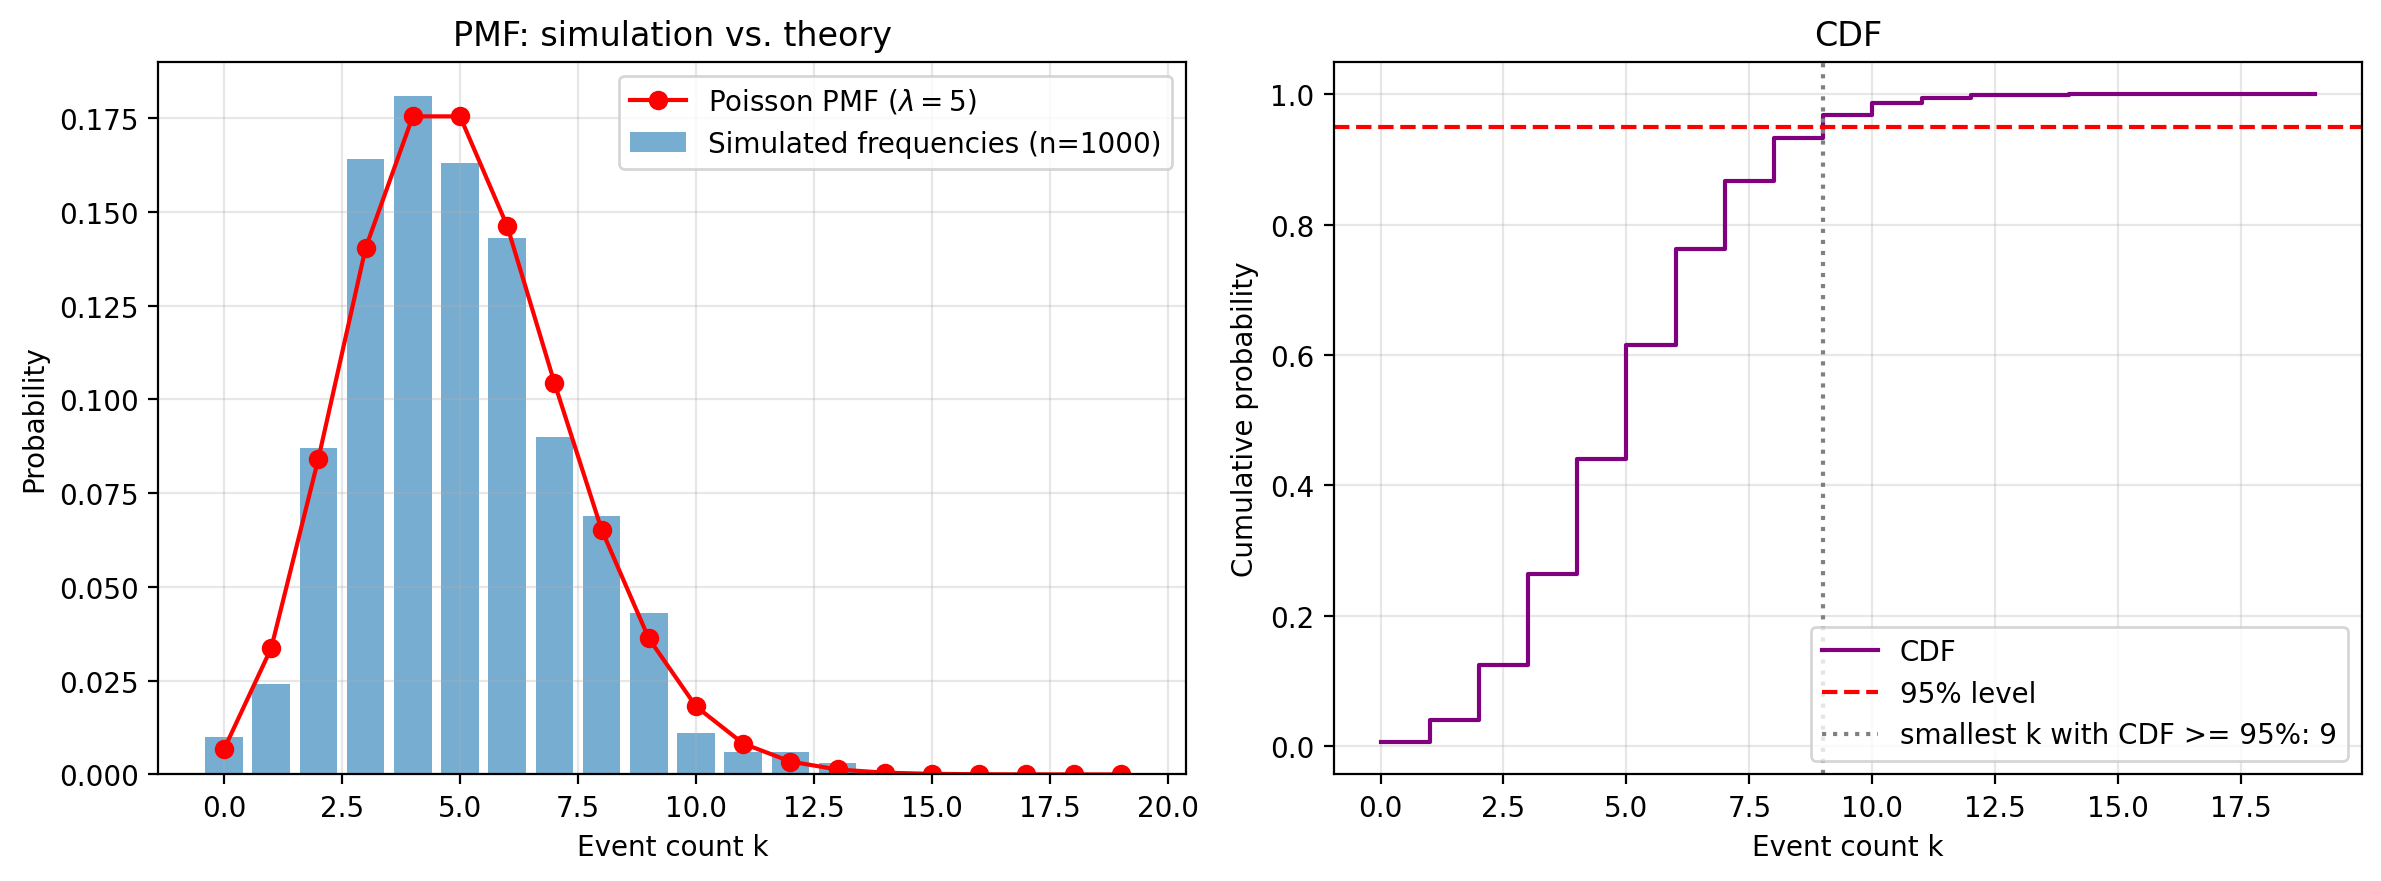

In [2]:
lam = 5
n = 1000
sample = rng.poisson(lam, n)

k = np.arange(0, 20)
emp_pmf = np.bincount(sample, minlength=k.size)[:k.size] / n

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

# Left: observed frequencies vs. theoretical PMF
ax[0].bar(k, emp_pmf, width=0.8, alpha=0.6, label="Simulated frequencies (n=1000)")
ax[0].plot(k, poisson.pmf(k, lam), "ro-", label=r"Poisson PMF ($\lambda=5$)")
ax[0].set_xlabel("Event count k")
ax[0].set_ylabel("Probability")
ax[0].set_title("PMF: simulation vs. theory")
ax[0].legend()

# Right: CDF and the smallest k reaching 95%
k95 = int(poisson.ppf(0.95, lam))
ax[1].step(k, poisson.cdf(k, lam), where="post", color="purple", label="CDF")
ax[1].axhline(0.95, color="red", ls="--", label="95% level")
ax[1].axvline(k95, color="gray", ls=":", label=f"smallest k with CDF >= 95%: {k95}")
ax[1].set_xlabel("Event count k")
ax[1].set_ylabel("Cumulative probability")
ax[1].set_title("CDF")
ax[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

print("sample mean    :", sample.mean(), "  (theory:", lam, ")")
print("sample variance:", round(sample.var(ddof=1), 3), "  (theory:", lam, ")")
print("P(X <= k95)    :", round(poisson.cdf(k95, lam), 4))
print("CDF = incomplete-gamma identity holds:",
      np.allclose(poisson.cdf(k, lam), gammaincc(k + 1, lam)))

**Results.** The simulated frequencies follow the theoretical PMF, and the sample mean and variance are both close to $\lambda=5$ (the *equidispersion* property). The CDF crosses 95% at $k=9$.

## 2. Reliability and hazard functions

There are two different things one can mean, and the first version of the paper mixed them up.

**(A) Count as a discrete "lifetime".** Treat the count $k$ as the index. Then
$S(k)=P(X>k)$ and the discrete hazard is the *conditional* probability
$$h(k)=P(X=k\mid X\ge k)=\frac{P(X=k)}{P(X\ge k)}\in(0,1].$$
Dividing by $P(X>k)$ instead (the old formula) is not a conditional probability and can exceed 1 — the grey curve below shows it.

**(B) Waiting time in a Poisson process.** With rate $\lambda$ events per unit time, the time to the first event is exponential:
$R(t)=P(T>t)=P(N(t)=0)=e^{-\lambda t}$ and the hazard is the constant $Z(t)=\lambda$ (memorylessness).

h(0) = e^-lambda = 0.00674 = 0.00674
max of correct hazard: 0.7537 | max of invalid ratio: 3.06
hazard is increasing: True


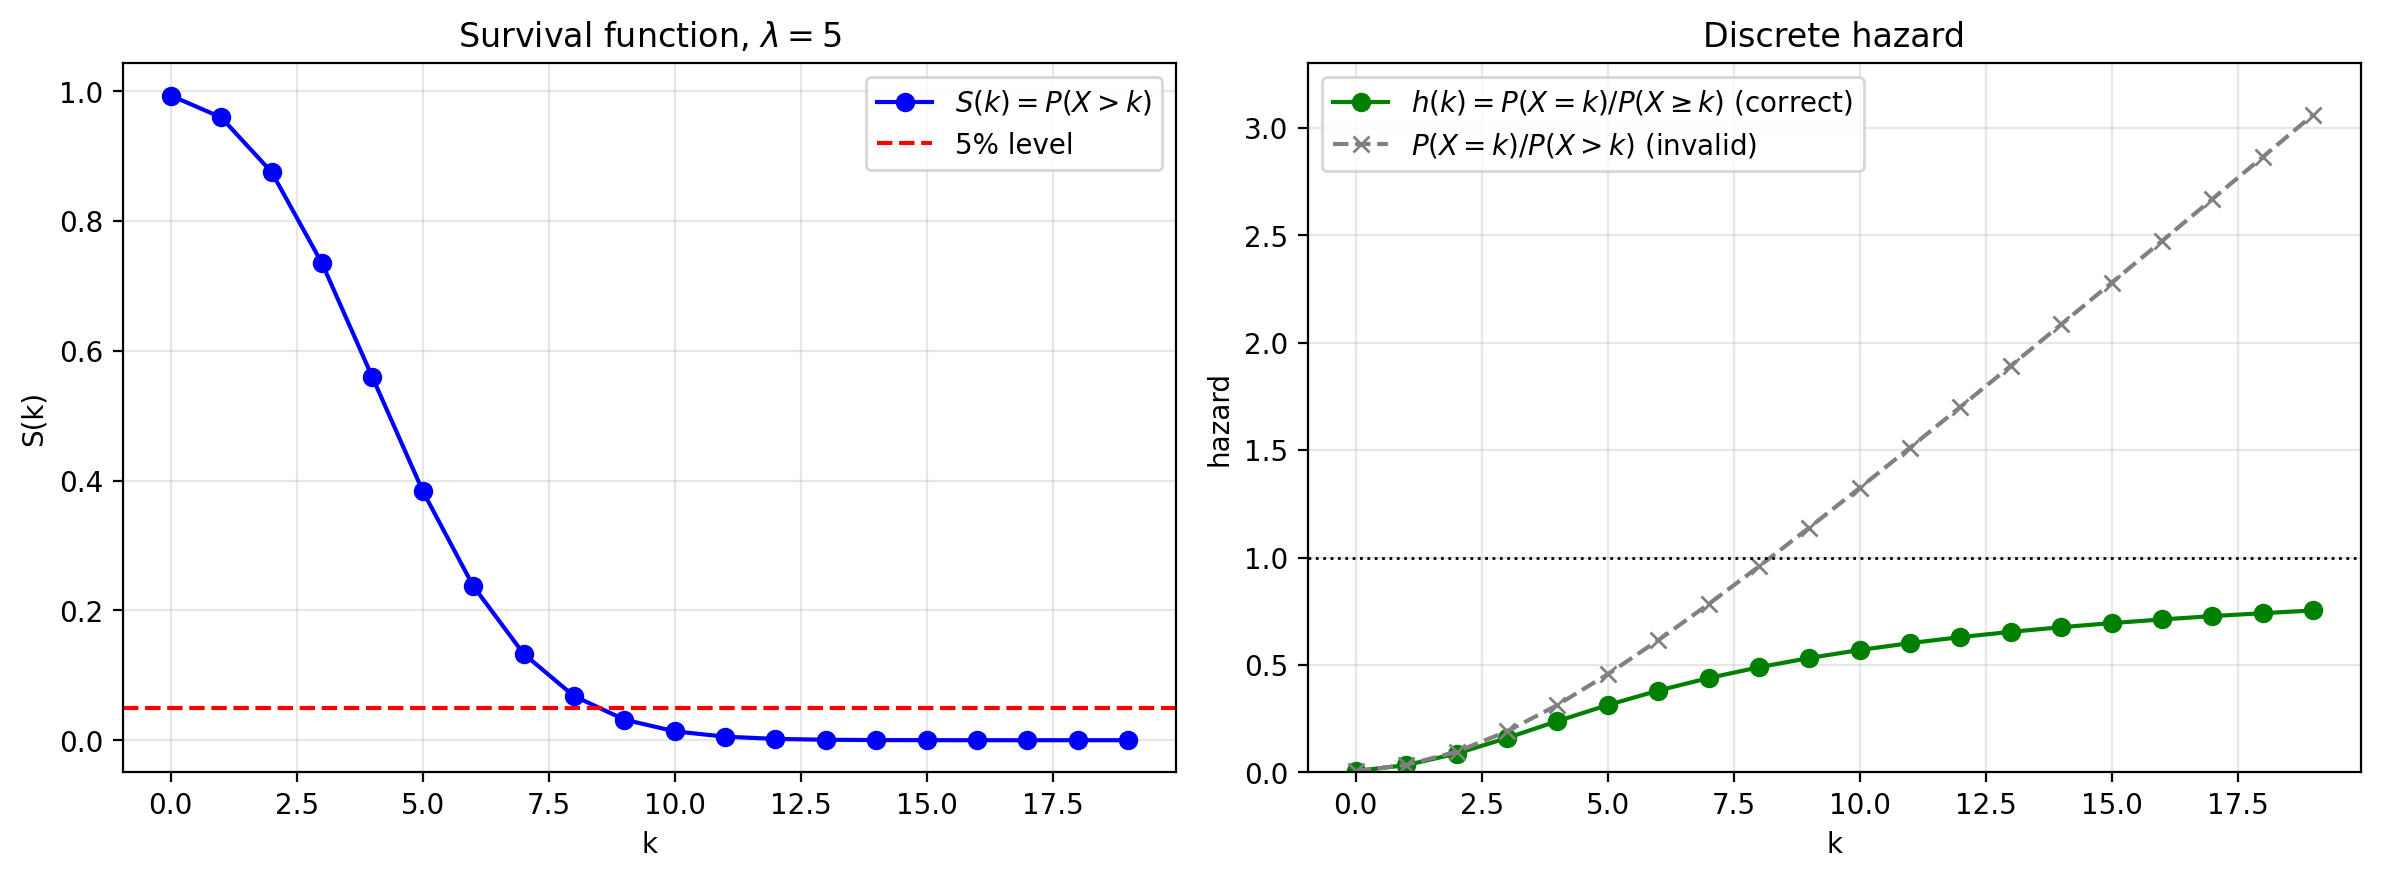

In [3]:
k = np.arange(0, 20)
surv = poisson.sf(k, lam)                              # S(k) = P(X > k)
hazard = poisson.pmf(k, lam) / poisson.sf(k - 1, lam)  # h(k) = P(X=k) / P(X>=k)
wrong = poisson.pmf(k, lam) / poisson.sf(k, lam)       # P(X=k) / P(X>k)  -> NOT a probability

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

ax[0].plot(k, surv, "bo-", label=r"$S(k)=P(X>k)$")
ax[0].axhline(0.05, color="red", ls="--", label="5% level")
ax[0].set_xlabel("k")
ax[0].set_ylabel("S(k)")
ax[0].set_title(r"Survival function, $\lambda=5$")
ax[0].legend()

ax[1].plot(k, hazard, "go-", label=r"$h(k)=P(X=k)/P(X\geq k)$ (correct)")
ax[1].plot(k, wrong, color="gray", ls="--", marker="x", label=r"$P(X=k)/P(X>k)$ (invalid)")
ax[1].axhline(1, color="black", ls=":", lw=1)
ax[1].set_ylim(0, 3.3)
ax[1].set_xlabel("k")
ax[1].set_ylabel("hazard")
ax[1].set_title("Discrete hazard")
ax[1].legend(loc="upper left")

plt.tight_layout()
plt.show()

print("h(0) = e^-lambda =", round(hazard[0], 5), "=", round(np.exp(-lam), 5))
print("max of correct hazard:", round(hazard.max(), 4), "| max of invalid ratio:", round(wrong.max(), 2))
print("hazard is increasing:", bool(np.all(np.diff(hazard) > 0)))

mean waiting time: simulated 0.2008 | theory 1/lambda = 0.2


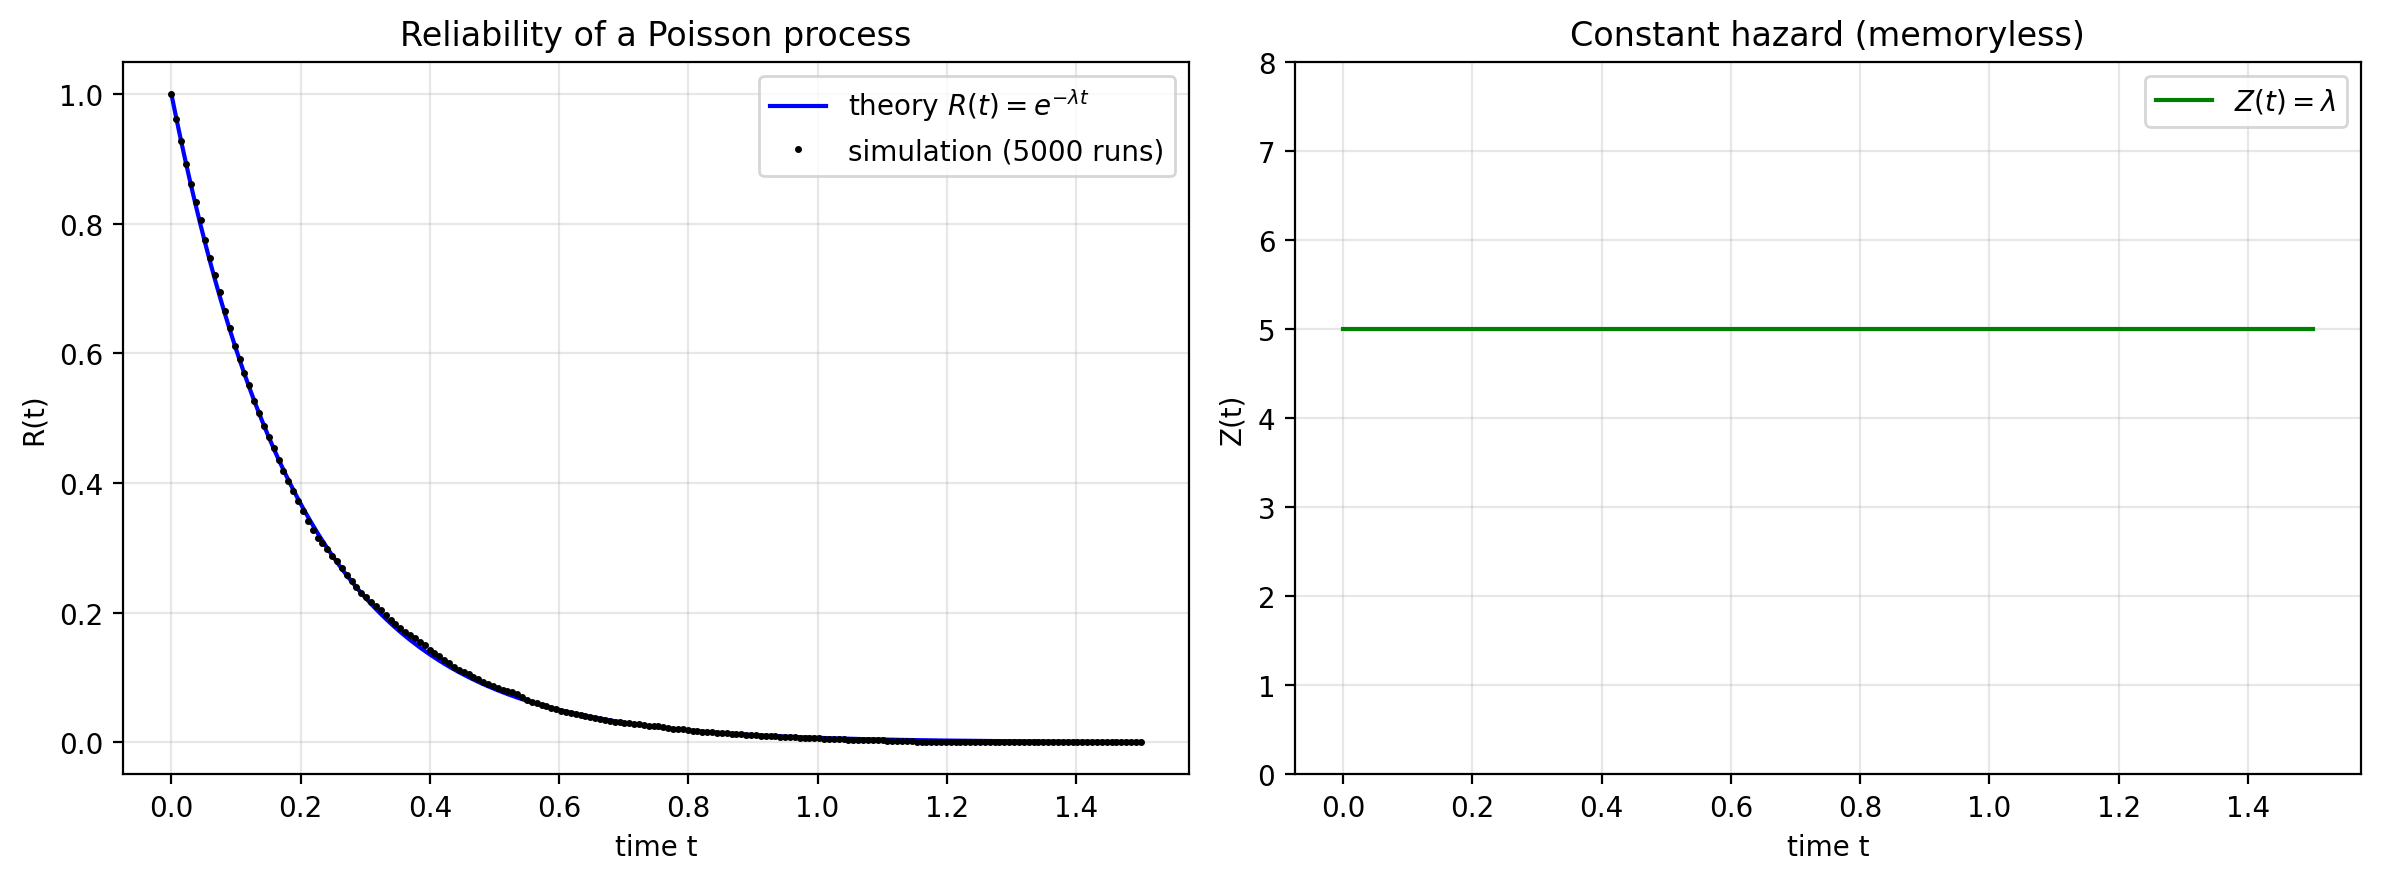

In [4]:
rate = 5.0                                   # events per unit time
t = np.linspace(0, 1.5, 200)

T = rng.exponential(1 / rate, 5000)          # simulated waiting times to the first event
R_emp = np.array([(T > ti).mean() for ti in t])
R_th = np.exp(-rate * t)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

ax[0].plot(t, R_th, "b-", label=r"theory $R(t)=e^{-\lambda t}$")
ax[0].plot(t, R_emp, "k.", ms=3, label="simulation (5000 runs)")
ax[0].set_xlabel("time t")
ax[0].set_ylabel("R(t)")
ax[0].set_title("Reliability of a Poisson process")
ax[0].legend()

ax[1].plot(t, np.full_like(t, rate), "g-", label=r"$Z(t)=\lambda$")
ax[1].set_ylim(0, 8)
ax[1].set_xlabel("time t")
ax[1].set_ylabel("Z(t)")
ax[1].set_title("Constant hazard (memoryless)")
ax[1].legend()

plt.tight_layout()
plt.show()

print("mean waiting time: simulated", round(T.mean(), 4), "| theory 1/lambda =", 1 / rate)

**Results.** In (A) the correct hazard starts at $e^{-\lambda}$, increases with $k$ and stays below 1, while the invalid ratio blows up past 3. In (B) the simulated survival curve sits on $e^{-\lambda t}$ and the hazard is flat at $\lambda$.

## 3. Relationships with other distributions

- **Binomial → Poisson:** $\text{Bin}(n,p)$ with $np=\lambda$ fixed, $n$ large.
- **Poisson → Normal:** for large $\lambda$, $\text{Poisson}(\lambda)\approx N(\lambda,\lambda)$; a continuity correction ($k+\tfrac12$) improves the CDF approximation.

total variation distance, Bin(1000,0.005) vs Poisson(5): 0.00123
lambda=  5: max CDF error of the normal approximation = 0.0290
lambda= 30: max CDF error of the normal approximation = 0.0121
lambda=100: max CDF error of the normal approximation = 0.0066


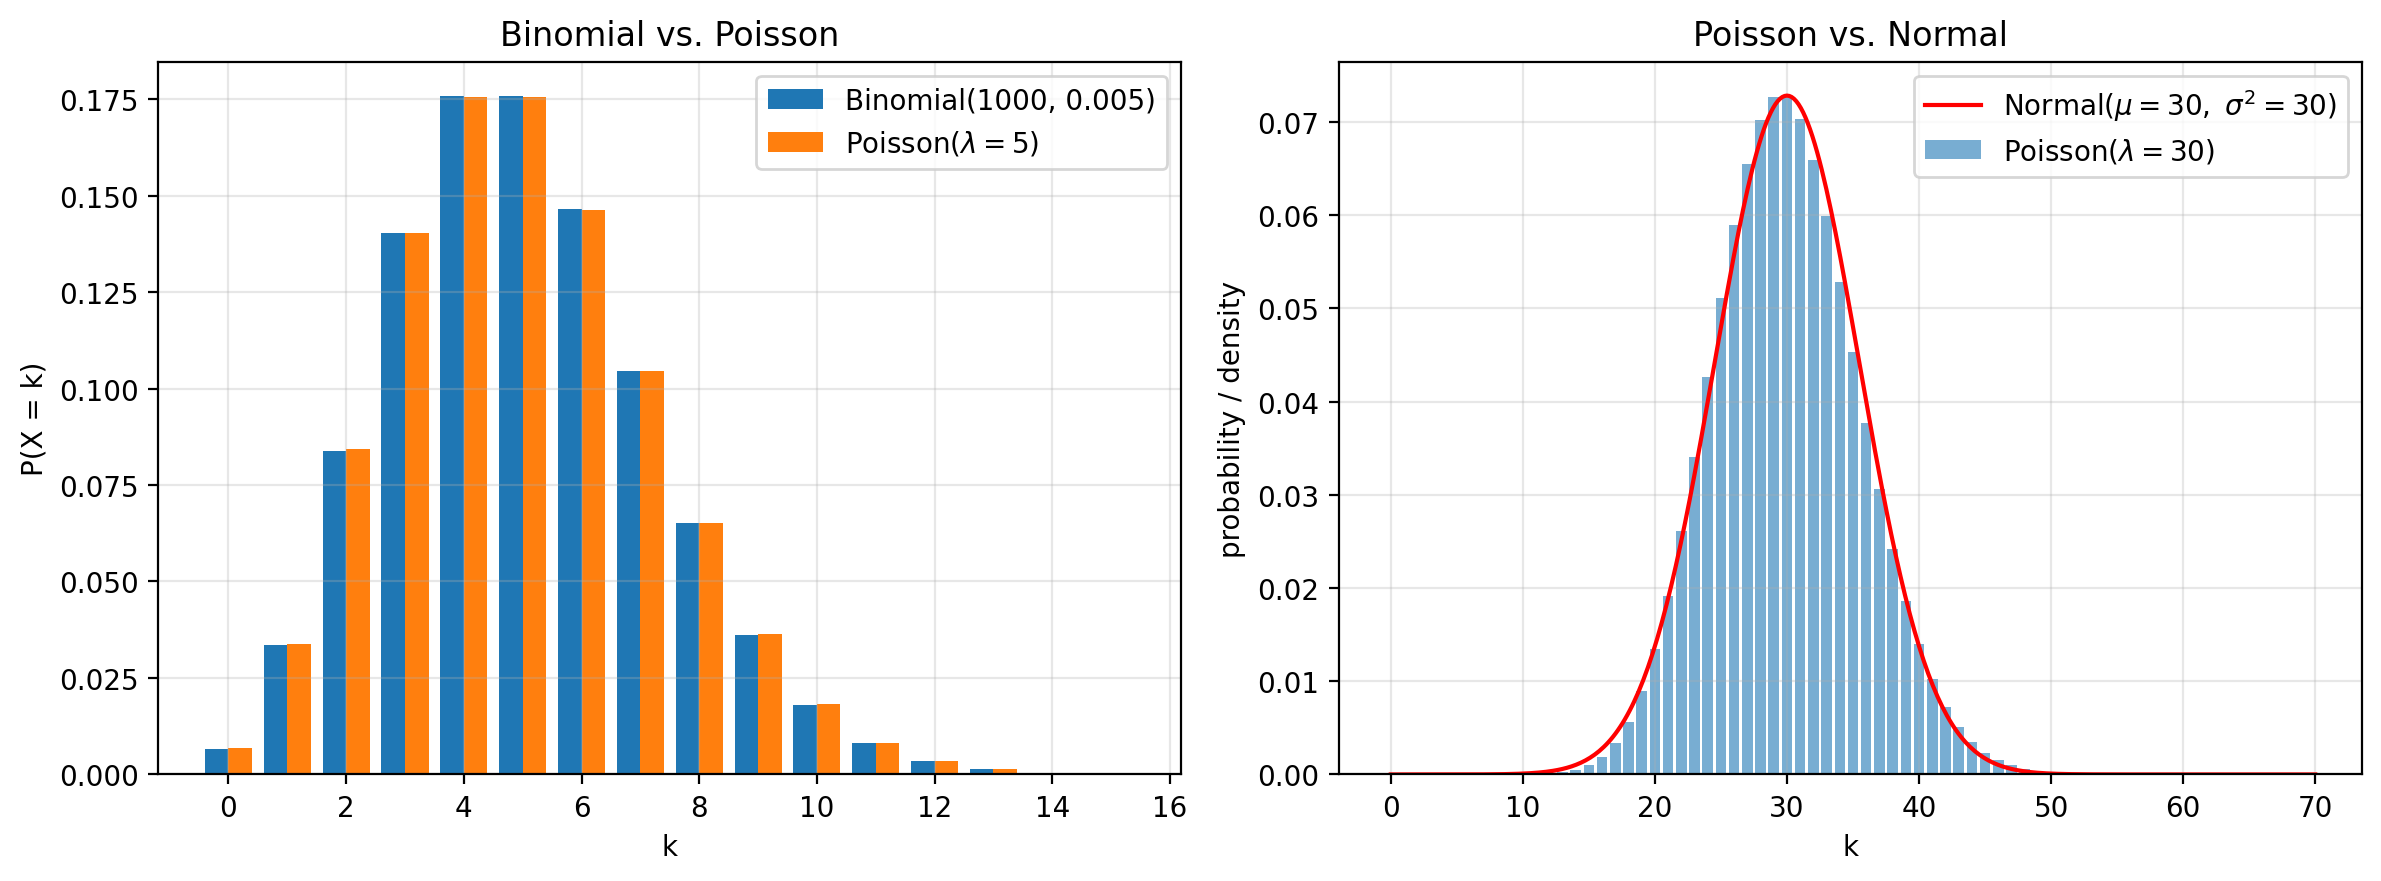

In [5]:
# (a) Binomial(n=1000, p=0.005) vs Poisson(5)
n_trials, p = 1000, 0.005
kb = np.arange(0, 16)
tv = 0.5 * np.abs(binom.pmf(kb, n_trials, p) - poisson.pmf(kb, n_trials * p)).sum()

# (b) Poisson(30) vs Normal(30, 30)
lam_b = 30
kn = np.arange(0, 70)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

ax[0].bar(kb - 0.2, binom.pmf(kb, n_trials, p), width=0.4, label="Binomial(1000, 0.005)")
ax[0].bar(kb + 0.2, poisson.pmf(kb, n_trials * p), width=0.4, label=r"Poisson($\lambda=5$)")
ax[0].set_xlabel("k")
ax[0].set_ylabel("P(X = k)")
ax[0].set_title("Binomial vs. Poisson")
ax[0].legend()

ax[1].bar(kn, poisson.pmf(kn, lam_b), alpha=0.6, label=r"Poisson($\lambda=30$)")
xs = np.linspace(0, 70, 400)
ax[1].plot(xs, norm.pdf(xs, lam_b, np.sqrt(lam_b)), "r-", label=r"Normal($\mu=30,\ \sigma^2=30$)")
ax[1].set_xlabel("k")
ax[1].set_ylabel("probability / density")
ax[1].set_title("Poisson vs. Normal")
ax[1].legend()

plt.tight_layout()
plt.show()

print("total variation distance, Bin(1000,0.005) vs Poisson(5):", round(tv, 5))
for lam_ in (5, 30, 100):
    ks = np.arange(0, int(lam_ + 8 * np.sqrt(lam_)))
    exact = poisson.cdf(ks, lam_)
    approx = norm.cdf((ks + 0.5 - lam_) / np.sqrt(lam_))
    print(f"lambda={lam_:>3}: max CDF error of the normal approximation = {np.abs(exact - approx).max():.4f}")

## 4. Poisson regression and applications

**Model.** For counts $y_i$ with covariates $x_i$:
$$y_i\sim\text{Poisson}(\mu_i),\qquad \log\mu_i=x_i^{\top}\beta .$$
`sm.GLM(..., family=sm.families.Poisson())` fits $\beta$ by maximum likelihood (IRLS) with the canonical log link, so $e^{\beta_j}$ is the *multiplicative* change in the expected count per unit change of $x_j$.
Cyclic patterns are modelled with Fourier terms $\sin(2\pi hx/P),\cos(2\pi hx/P)$.

**Diagnostic.** Pearson $\chi^2$ divided by the residual degrees of freedom should be close to 1; values well above 1 indicate *overdispersion* (variance > mean), where Poisson standard errors are too small.

> All datasets below are **synthetic**, generated with known true coefficients so we can check that the model recovers them.

In [6]:
def fourier_design(x, period, harmonics=1):
    # Intercept + sin/cos terms: lets a log-linear model learn a cyclic pattern.
    cols = [np.ones(len(x))]
    for h in range(1, harmonics + 1):
        cols += [np.sin(2 * np.pi * h * x / period), np.cos(2 * np.pi * h * x / period)]
    return np.column_stack(cols)

def dispersion(result):
    # Pearson chi-square / residual d.o.f.  (about 1 if the Poisson assumption holds)
    return result.pearson_chi2 / result.df_resid

### 4.1 Customer-support call volume

**Use case:** staffing. Calls per hour follow a daily cycle; Poisson regression with one harmonic learns the expected load for each hour.

true beta     : [ 1.5  0.5 -0.5]
estimated beta: [ 1.497  0.497 -0.496]
dispersion    : 1.033
busiest hour (fit): 9 | expected calls: 9.01


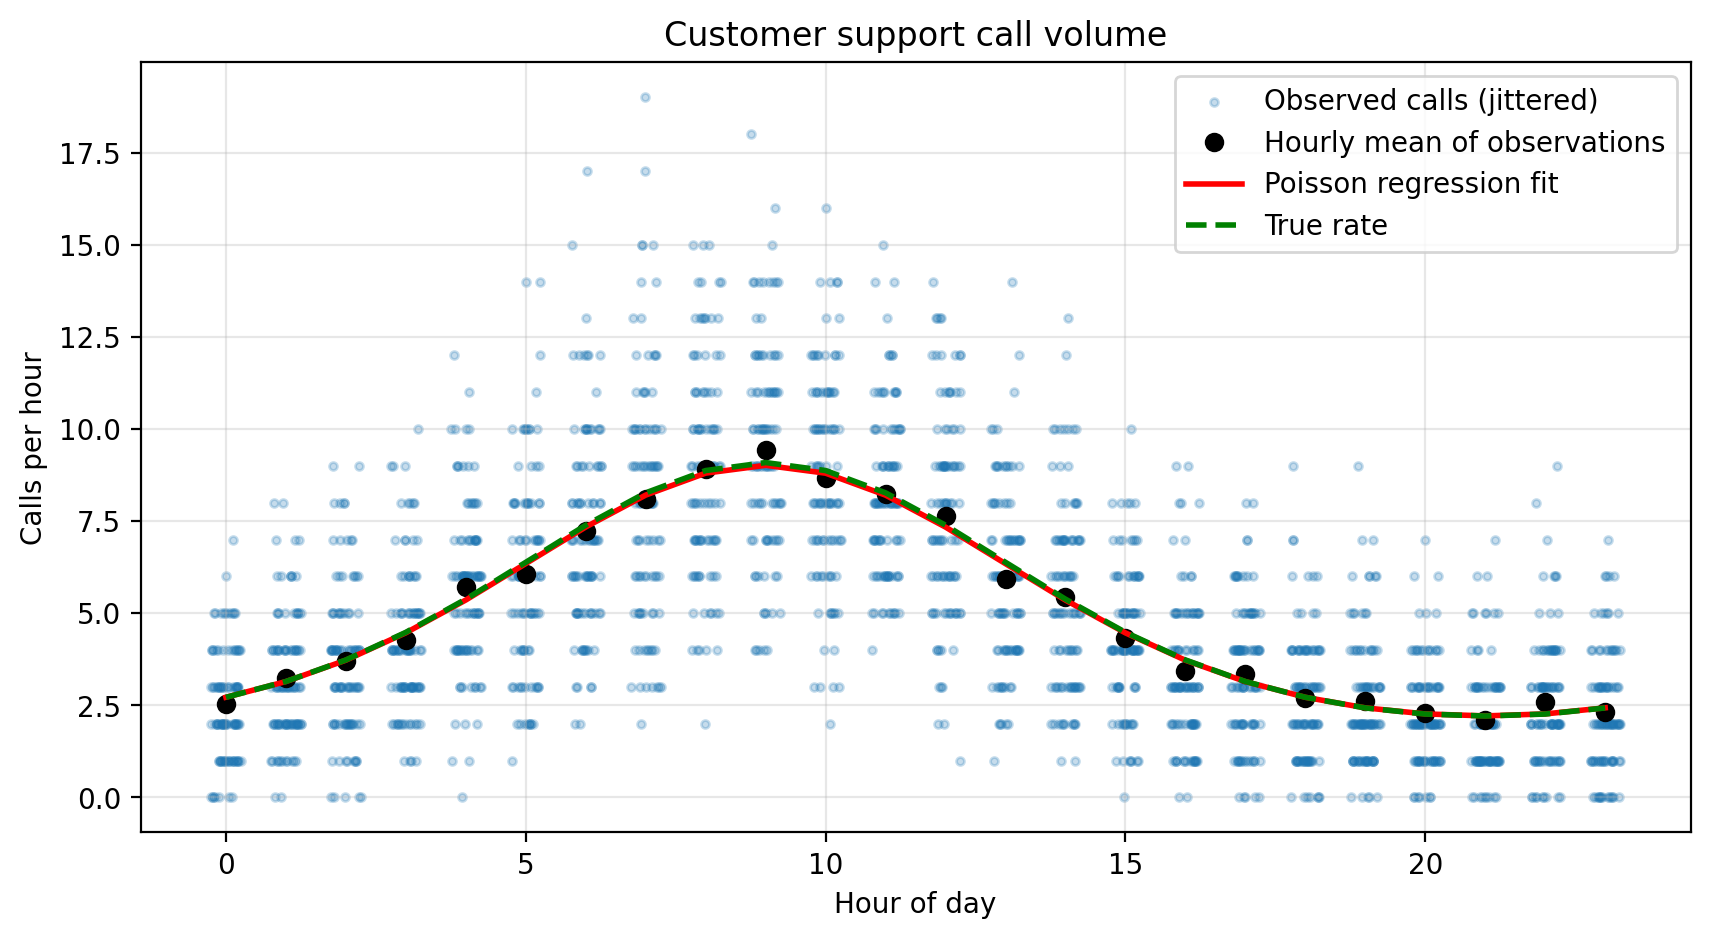

In [7]:
hour = np.tile(np.arange(24), 100)                 # 100 days of hourly counts
X = fourier_design(hour, period=24, harmonics=1)
beta_true = np.array([1.5, 0.5, -0.5])             # true log-rate coefficients
calls = rng.poisson(np.exp(X @ beta_true))

model = sm.GLM(calls, X, family=sm.families.Poisson()).fit()
print("true beta     :", beta_true)
print("estimated beta:", np.round(model.params, 3))
print("dispersion    :", round(dispersion(model), 3))

hours = np.arange(24)
Xh = fourier_design(hours, 24, 1)
fitted = np.exp(Xh @ model.params)
true_rate = np.exp(Xh @ beta_true)
observed_mean = calls.reshape(100, 24).mean(axis=0)

plt.figure(figsize=(10, 5))
plt.scatter(hour + rng.uniform(-0.25, 0.25, hour.size), calls, s=8, alpha=0.25, label="Observed calls (jittered)")
plt.plot(hours, observed_mean, "ko", label="Hourly mean of observations")
plt.plot(hours, fitted, "r-", lw=2, label="Poisson regression fit")
plt.plot(hours, true_rate, "g--", lw=2, label="True rate")
plt.title("Customer support call volume")
plt.xlabel("Hour of day")
plt.ylabel("Calls per hour")
plt.legend()
plt.show()

print("busiest hour (fit):", int(hours[fitted.argmax()]), "| expected calls:", round(fitted.max(), 2))

**Results.** The estimated coefficients are close to the true ones, the fitted curve follows the hourly means and the dispersion is about 1, so the Poisson assumption is adequate here. The model gives a *different* expected load for every hour — which a constant-rate simulation (as in the first version) could never show.

### 4.2 Network security: anomaly detection with Poisson tail probabilities

**Use case:** flag time windows whose breach count is implausibly high under the normal rate.
Estimate $\hat\lambda$ on a clean training period, then flag a window with count $k$ when $P(X\ge k\mid\hat\lambda)<\alpha$.
Unlike an Isolation Forest with a fixed `contamination`, the false-alarm rate is controlled by $\alpha$ and does not force 5% of the data to be "anomalous".

lambda_hat = 0.492 | alert when count >= 5
true attacks: 8 | detected: 6 | false alarms: 0 | missed: 2


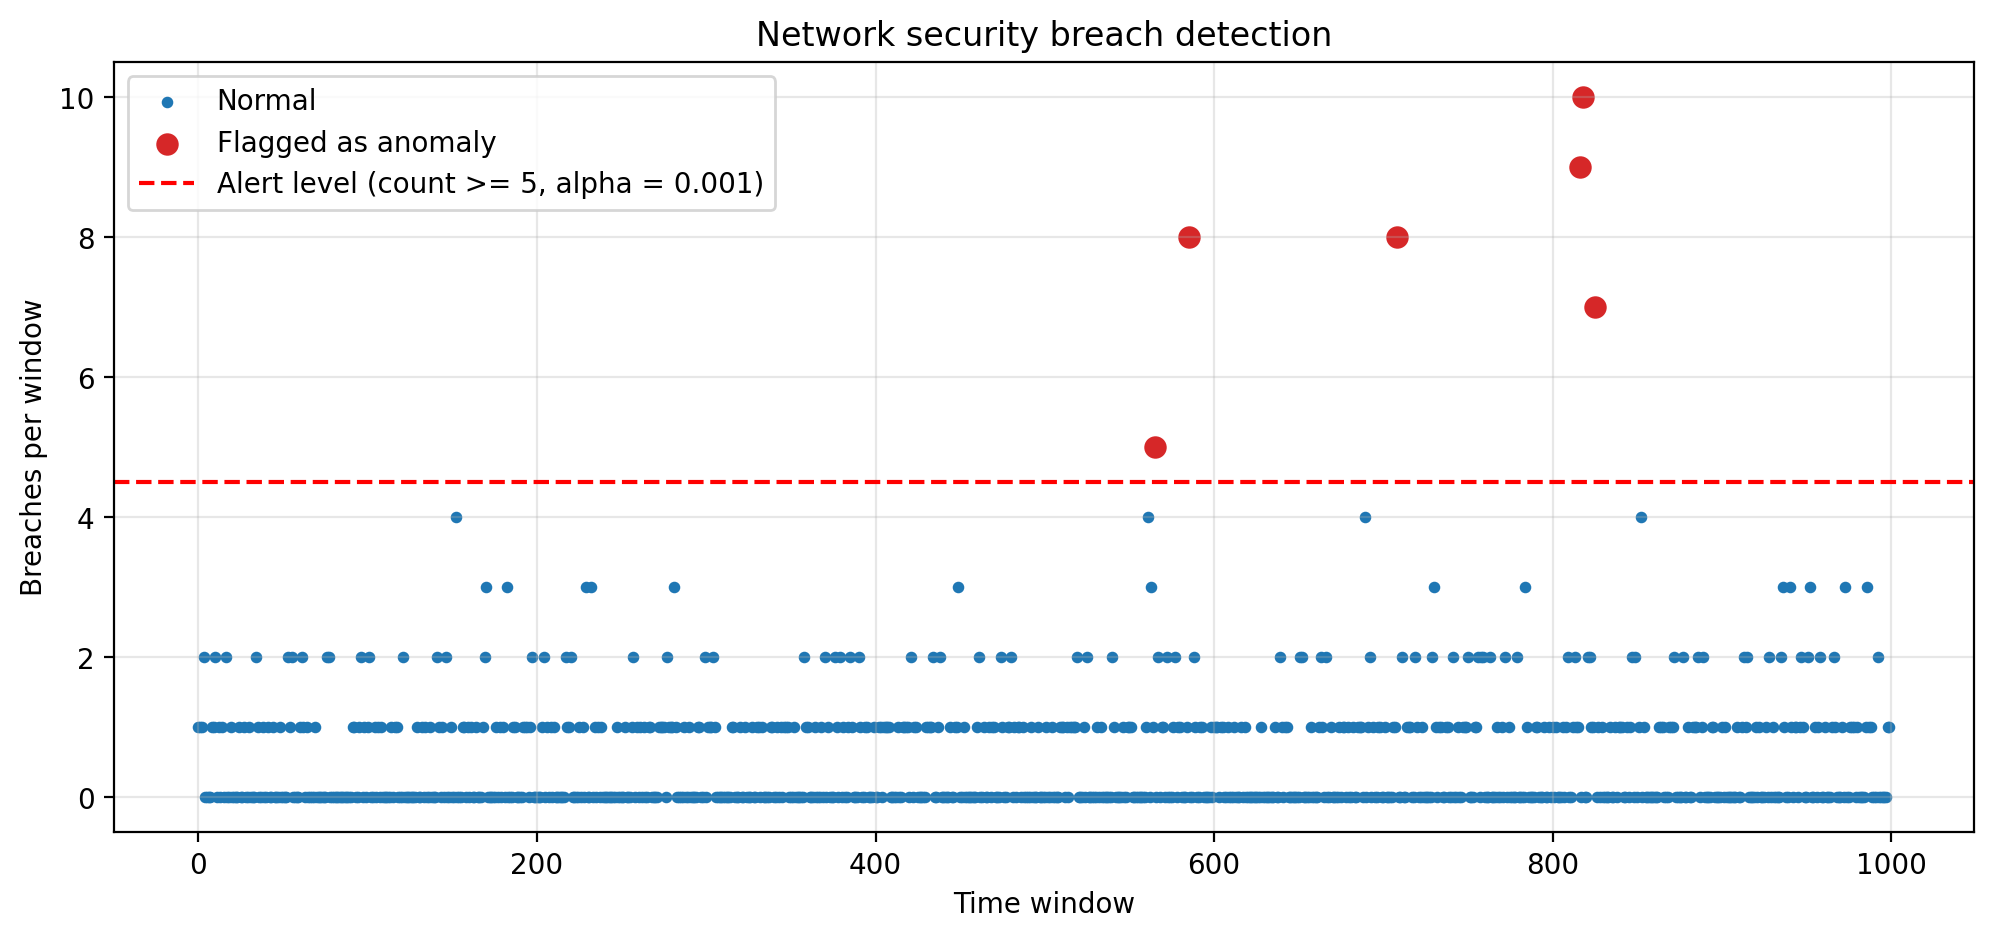

In [8]:
n_windows = 1000
counts = rng.poisson(0.5, n_windows)                         # normal behaviour: 0.5 breaches / window
attack_idx = rng.choice(np.arange(500, n_windows), 8, replace=False)
counts[attack_idx] = rng.poisson(6, 8)                       # injected attack windows
is_attack = np.zeros(n_windows, dtype=bool)
is_attack[attack_idx] = True

lam_hat = counts[:500].mean()                                # clean training period
alpha = 1e-3
flag = poisson.sf(counts - 1, lam_hat) < alpha               # P(X >= k) < alpha
k_crit = int(np.argmax(poisson.sf(np.arange(50) - 1, lam_hat) < alpha))

tp = int((flag & is_attack).sum())
fp = int((flag & ~is_attack).sum())
fn = int((~flag & is_attack).sum())
print("lambda_hat =", round(lam_hat, 3), "| alert when count >=", k_crit)
print(f"true attacks: {is_attack.sum()} | detected: {tp} | false alarms: {fp} | missed: {fn}")

plt.figure(figsize=(12, 5))
plt.scatter(np.where(~flag)[0], counts[~flag], s=10, color="tab:blue", label="Normal")
plt.scatter(np.where(flag)[0], counts[flag], s=50, color="tab:red", label="Flagged as anomaly")
plt.axhline(k_crit - 0.5, color="red", ls="--", label=f"Alert level (count >= {k_crit}, alpha = {alpha})")
plt.title("Network security breach detection")
plt.xlabel("Time window")
plt.ylabel("Breaches per window")
plt.legend()
plt.show()

**Results.** With $\hat\lambda\approx 0.5$ and $\alpha=0.001$ the alert level is 5 breaches per window. The rule detects most injected attacks and raises essentially no false alarms. Attacks that happen to produce small counts (e.g. 2–4) are missed — that is the price of a strict $\alpha$, and the trade-off can be tuned explicitly.

### 4.3 Traffic flow

**Use case:** vehicle arrivals at an intersection have morning and evening peaks. Two Fourier harmonics capture a double-peaked daily profile.

true beta     : [ 2.6  -0.06 -0.24 -0.2  -0.35]
estimated beta: [ 2.601 -0.062 -0.243 -0.2   -0.343]
dispersion    : 1.001
busiest hour (fit): 8 | expected vehicles: 20.4


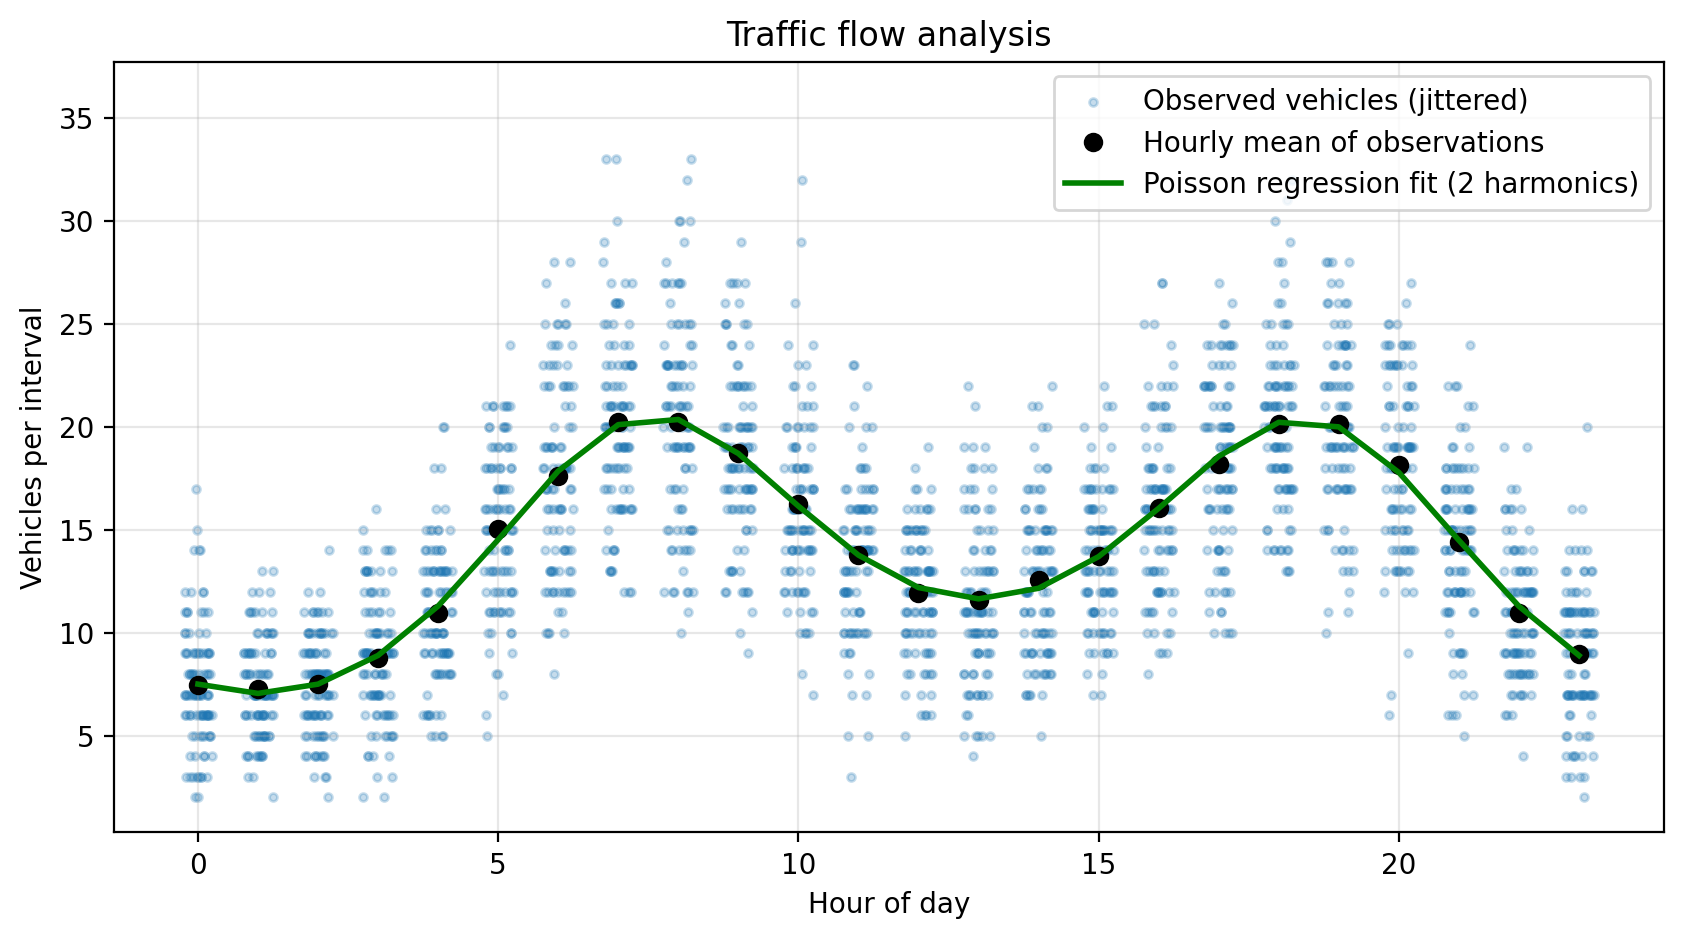

In [9]:
time_of_day = np.tile(np.arange(24), 100)
X = fourier_design(time_of_day, period=24, harmonics=2)
beta_true = np.array([2.6, -0.06, -0.24, -0.2, -0.35])   # peaks near 08:00 and 18:00
vehicles = rng.poisson(np.exp(X @ beta_true))

traffic_model = sm.GLM(vehicles, X, family=sm.families.Poisson()).fit()
print("true beta     :", beta_true)
print("estimated beta:", np.round(traffic_model.params, 3))
print("dispersion    :", round(dispersion(traffic_model), 3))

hours = np.arange(24)
Xh = fourier_design(hours, 24, 2)
fitted = np.exp(Xh @ traffic_model.params)
observed_mean = vehicles.reshape(100, 24).mean(axis=0)

plt.figure(figsize=(10, 5))
plt.scatter(time_of_day + rng.uniform(-0.25, 0.25, time_of_day.size), vehicles, s=8, alpha=0.25,
            label="Observed vehicles (jittered)")
plt.plot(hours, observed_mean, "ko", label="Hourly mean of observations")
plt.plot(hours, fitted, "g-", lw=2, label="Poisson regression fit (2 harmonics)")
plt.title("Traffic flow analysis")
plt.xlabel("Hour of day")
plt.ylabel("Vehicles per interval")
plt.legend()
plt.show()

print("busiest hour (fit):", int(hours[fitted.argmax()]), "| expected vehicles:", round(fitted.max(), 1))

**Results.** The two-harmonic model recovers a double-peaked daily profile and the coefficients are close to the truth; the dispersion is about 1. A single harmonic could not represent two peaks, which is why `harmonics=2` is used here.

### 4.4 Disease incidence and overdispersion

**Use case:** weekly case counts with a seasonal pattern. Real surveillance counts are usually **overdispersed** (variance > mean) because cases cluster. We simulate this with a Negative Binomial and show what happens when a plain Poisson model is used, and how a quasi-Poisson correction (`scale="X2"`) repairs the standard errors.

true beta        : [1.2 0.7 0.4]
estimated beta   : [1.302 0.753 0.292]
dispersion       : 4.24 (1 = Poisson-consistent)
std errors Poisson      : [0.045 0.061 0.057]
std errors quasi-Poisson: [0.093 0.125 0.118]
share of weeks inside the Poisson 95% band: 0.80 (expected about 0.95)


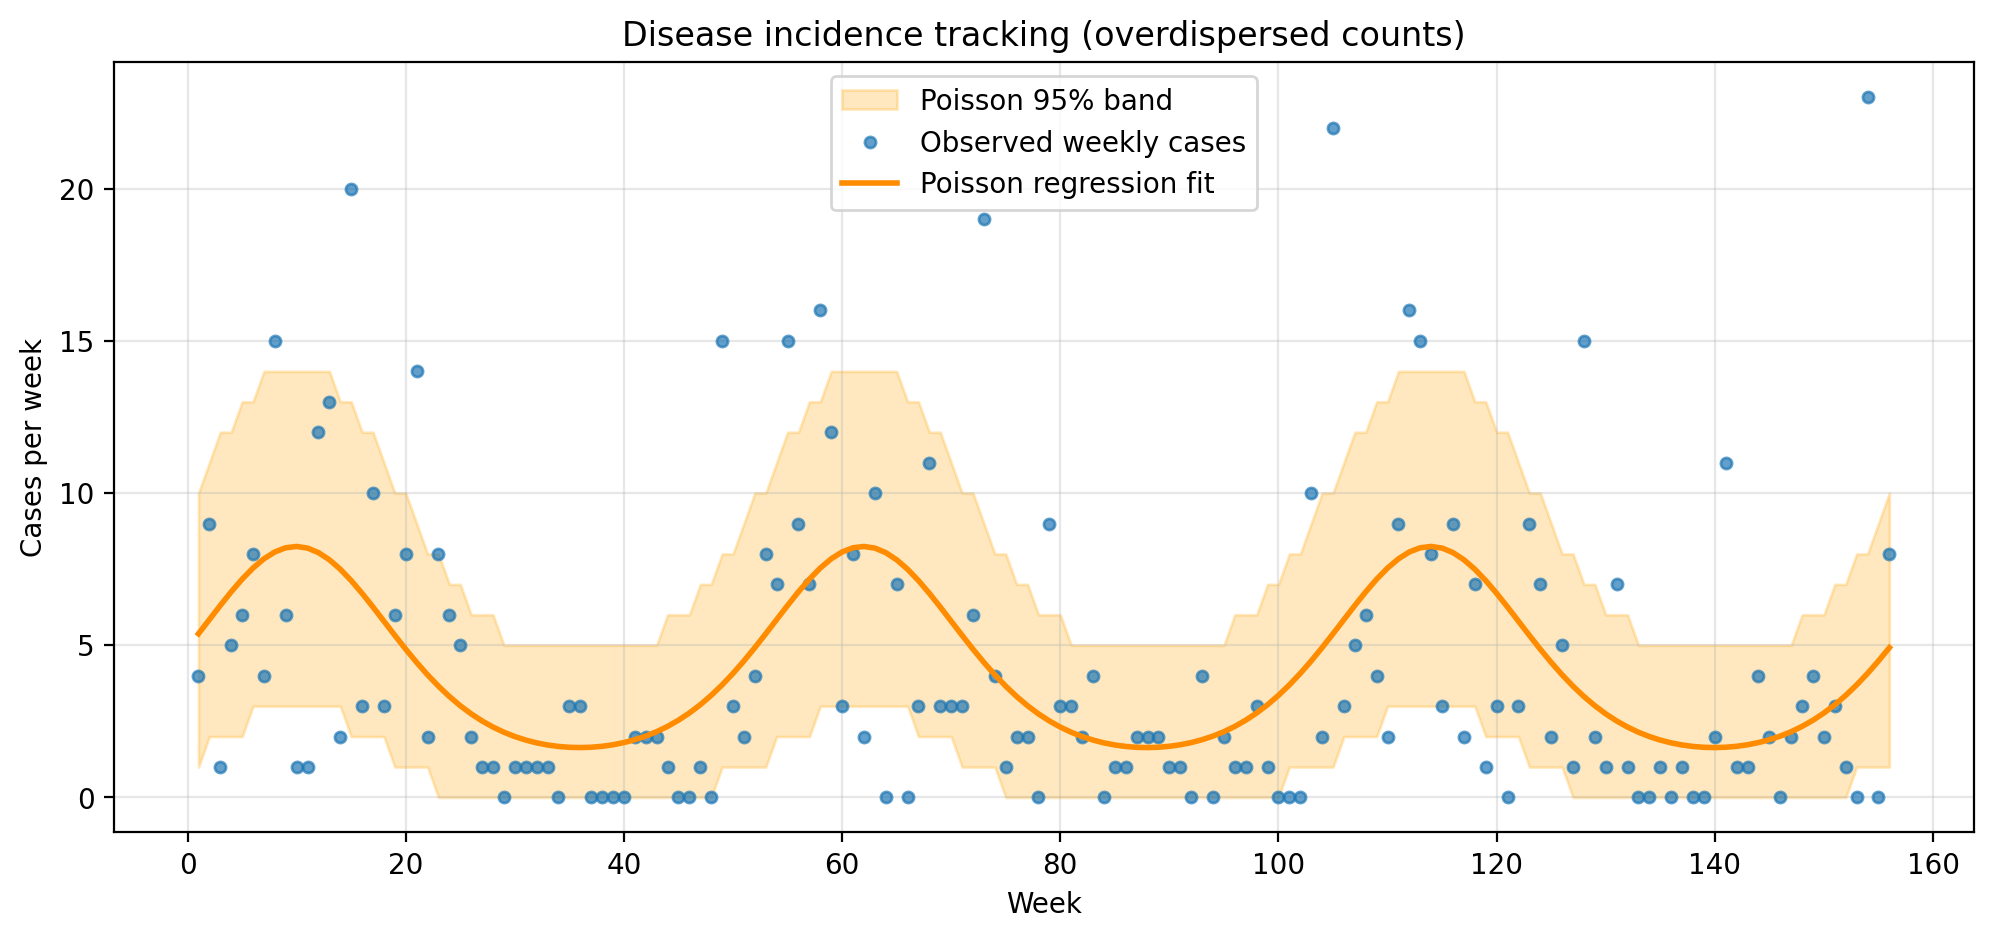

In [10]:
weeks = np.arange(1, 157)                         # three years of weekly counts
X = fourier_design(weeks, period=52, harmonics=1)
beta_true = np.array([1.2, 0.7, 0.4])
mu = np.exp(X @ beta_true)
r = 1.5                                           # NB size: Var = mu + mu^2 / r  (overdispersed)
cases = rng.negative_binomial(r, r / (r + mu))

pois = sm.GLM(cases, X, family=sm.families.Poisson()).fit()
quasi = sm.GLM(cases, X, family=sm.families.Poisson()).fit(scale="X2")

print("true beta        :", beta_true)
print("estimated beta   :", np.round(pois.params, 3))
print("dispersion       :", round(dispersion(pois), 2), "(1 = Poisson-consistent)")
print("std errors Poisson      :", np.round(pois.bse, 3))
print("std errors quasi-Poisson:", np.round(quasi.bse, 3))

fitted = pois.fittedvalues
lo, hi = poisson.ppf(0.025, fitted), poisson.ppf(0.975, fitted)
inside = np.mean((cases >= lo) & (cases <= hi))
print(f"share of weeks inside the Poisson 95% band: {inside:.2f} (expected about 0.95)")

plt.figure(figsize=(12, 5))
plt.fill_between(weeks, lo, hi, color="orange", alpha=0.25, label="Poisson 95% band")
plt.plot(weeks, cases, "o", ms=4, alpha=0.7, label="Observed weekly cases")
plt.plot(weeks, fitted, color="darkorange", lw=2, label="Poisson regression fit")
plt.title("Disease incidence tracking (overdispersed counts)")
plt.xlabel("Week")
plt.ylabel("Cases per week")
plt.legend()
plt.show()

**Results.** The coefficients are still estimated well, but the dispersion is well above 1, so the Poisson standard errors are too small and far fewer than 95% of weeks fall inside the Poisson band. The quasi-Poisson fit inflates the standard errors by $\sqrt{\text{dispersion}}$. A Negative Binomial model is the natural next step (see Future Work).

### 4.5 E-commerce clickstream

**Use case:** relate engagement (clicks) to session length. Here the clicks genuinely depend on the session time, $\log\mu=\beta_0+\beta_1\,\text{minutes}$, and $e^{\beta_1}$ is the multiplicative increase in expected clicks per extra minute.

true beta     : [0.5  0.06]
estimated beta: [0.517 0.059] | std errors: [0.029 0.003]
rate ratio per extra minute exp(beta1) = 1.061
dispersion    : 0.937


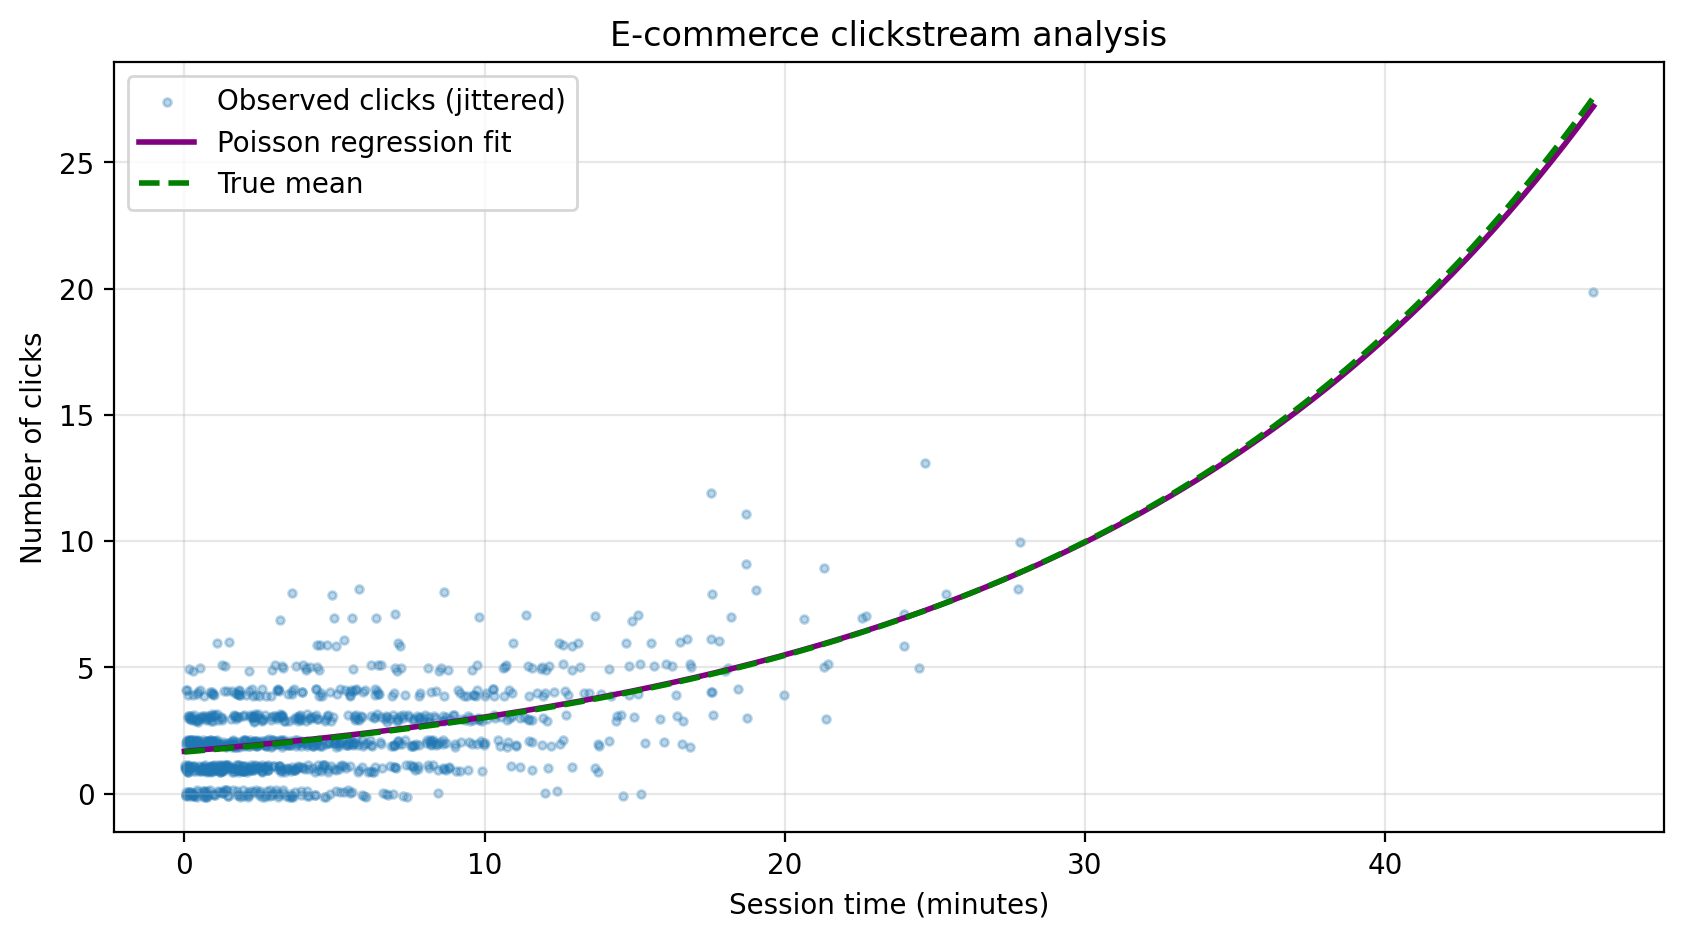

In [11]:
session_time = rng.exponential(scale=5, size=1000)            # minutes
X = np.column_stack([np.ones(1000), session_time])
beta_true = np.array([0.5, 0.06])
clicks = rng.poisson(np.exp(X @ beta_true))

click_model = sm.GLM(clicks, X, family=sm.families.Poisson()).fit()
b0, b1 = click_model.params
print("true beta     :", beta_true)
print("estimated beta:", np.round(click_model.params, 3), "| std errors:", np.round(click_model.bse, 3))
print("rate ratio per extra minute exp(beta1) =", round(np.exp(b1), 3))
print("dispersion    :", round(dispersion(click_model), 3))

grid = np.linspace(0, session_time.max(), 200)
plt.figure(figsize=(10, 5))
plt.scatter(session_time, clicks + rng.uniform(-0.15, 0.15, clicks.size), s=8, alpha=0.3,
            label="Observed clicks (jittered)")
plt.plot(grid, np.exp(b0 + b1 * grid), color="purple", lw=2, label="Poisson regression fit")
plt.plot(grid, np.exp(beta_true[0] + beta_true[1] * grid), "g--", lw=2, label="True mean")
plt.title("E-commerce clickstream analysis")
plt.xlabel("Session time (minutes)")
plt.ylabel("Number of clicks")
plt.legend()
plt.show()

**Results.** The fitted curve is increasing and close to the true mean; $e^{\hat\beta_1}\approx 1.06$ means each additional minute multiplies the expected number of clicks by about 6%. In the first version `clicks` was generated independently of `session_time`, so the "relationship" shown there was an artefact of the code.

---
## 5. Limitations and future work

- Poisson assumes independence, a constant rate inside each interval and mean = variance. Check the dispersion; use Negative Binomial or Zero-Inflated models when it fails.
- Use `offset=np.log(exposure)` in `sm.GLM` when intervals have different lengths or populations.
- A non-homogeneous Poisson process (time-varying $\lambda(t)$), Bayesian Gamma–Poisson models, real datasets, and an interactive dashboard are natural extensions.